# Sentinel-1 workflow (Copernicus)
Same steps as `Biomass_Downloader.ipynb`, for Sentinel-1 C-band GRD products (detected, ground range, VV+VH over land). The logic lives in the `biomass` package (`src/biomass`). Install once with `pip install -e ".[geo,dev]"`, edit only the configuration cell and run top to bottom.

### Copernicus account
Searching and the thumbnails need no account. The files themselves are served by the **Copernicus Data Space**, which needs its own free account (your MAAP `token.txt` does not work there): create one at https://dataspace.copernicus.eu.

**Recommended: save your login in `copernicus.txt`**, so you are never asked for it. Create a plain text file with that name in the project folder (the same folder as `token.txt`), with exactly two lines:

```
your.email@example.com
your-password
```

- Line 1: the e-mail of your Copernicus account. Line 2: its password. Nothing else.
- The file is listed in `.gitignore`, so git will not upload it. Never write the password in a notebook cell: notebooks are committed.

**Without the file**, the first download asks for the e-mail and password:
- They are kept in memory, so later downloads in the same session do not ask again.
- They are forgotten when the kernel restarts or when the configuration cell is run again; the next download then asks again.
- A wrong password is forgotten at once, so you are simply asked again.
- Nothing you type there is saved to disk.

Behind the scenes, the code logs in once and receives a temporary access key that it renews by itself while the notebook runs; you never have to log in again during a session.

In [1]:
from pathlib import Path
from biomass import (SentinelClient, SearchQuery, Downloader, sentinel_items_table, assets_table,
                     footprint_map, inspect_raster, plot_raster, raster_map)

# --- Configuration ---
QUERY = SearchQuery(
    collection="sentinel-1-grd",
    product_type="IW_GRDH_1S",                 # IW mode, high resolution (the usual one over land)
    date_start="2026-01-01",
    date_end="2026-07-01",
    bbox=[-60.6, -3.4, -59.8, -2.8],           # [min_lon, min_lat, max_lon, max_lat]
    aoi_file=None,                             # e.g. "my_area.geojson" (overrides bbox)
    extra_filters={},                          # e.g. {"sat:orbit_state": "descending", "sat:relative_orbit": 54}
    max_items=10,                              # results come newest first
)
ASSETS_TO_DOWNLOAD = ["vv", "vh"]               # one GeoTIFF per polarisation, about 0.6 GB each
OUTPUT_DIR = Path("../data/sentinel1")

client = SentinelClient()

## Explore

In [2]:
client.collections()

,id,title,extent.temporal.interval
0,sentinel-1-global-mosaics,Sentinel-1 Global Mosaics,"[[2020-01-01T00:00:00.000Z, None]]"
1,sentinel-1-grd,Sentinel-1 Ground Range Detected (GRD),"[[2014-10-04T03:12:47Z, None]]"
2,sentinel-1-slc,"Sentinel-1 Single Look Complex: IW, EW, SM","[[2014-10-04T03:06:54.705000Z, None]]"
3,sentinel-1-slc-wv,Sentinel-1 Single Look Complex: WV,"[[2014-10-04T03:06:54.705000Z, None]]"
4,sentinel-2-global-mosaics,Sentinel-2 Global Mosaics,"[[2020-01-01T00:00:00.000Z, None]]"
5,sentinel-2-gri-l1c,Sentinel-2 GRI L1C,"[[2015-07-06T10:57:26.420Z, 2018-09-06T08:25:5..."
6,sentinel-2-gri-l1c-gcp,Sentinel-2 GRI L1C GCP,"[[2015-06-23T01:52:00.000000Z, 9999-12-31T23:5..."
7,sentinel-2-l1c,Sentinel-2 Level-1C,"[[2015-06-27T10:25:31Z, None]]"
8,sentinel-2-l2a,Sentinel-2 Level-2A,"[[2015-06-27T10:25:31Z, None]]"


In [3]:
client.queryables(QUERY.collection)

,property,type,values,description
0,datetime,string,,Datetime
1,sat:relative_orbit,integer,,Satellite relative orbit number
2,sar:instrument_mode,string,"EW, IW, SM",SAR instrument mode
3,sat:orbit_state,string,"ascending, descending, geostationary",The state of the orbit: ascending or descendin...
4,processing:version,string,,Which software/processor version was used to g...
5,geometry,NaN,,Item Geometry
6,product:type,string,"EW_GRDH_1S, EW_GRDM_1S, IW_GRDH_1S, S1_GRDH_1S...",Product Type
7,id,string,,Item identifier
8,published,string,,Datetime
9,platform,string,"sentinel-1a, sentinel-1b, sentinel-1c",Satellite platform identifier


## Search

In [4]:
items = client.search(QUERY)
sentinel_items_table(items)

10 products fetched


<project folder>\.venv_biomass\Lib\site-packages\pystac_client\item_search.py:771: UserWarning: numberMatched or context.matched not in response
  warnings.warn("numberMatched or context.matched not in response")


,idx,id,start,platform,orbit,track,type,pols,assets
0,0,S1D_IW_GRDH_1SDV_20260629T094654_20260629T0947...,2026-06-29T09:46:54.195974Z,sentinel-1d,descending,83,IW_GRDH_1S,"VV,VH",14
1,1,S1A_IW_GRDH_1SDV_20260629T093922_20260629T0939...,2026-06-29T09:39:22.371910Z,sentinel-1a,descending,10,IW_GRDH_1S,"VV,VH",14
2,2,S1A_IW_GRDH_1SDV_20260622T094734_20260622T0947...,2026-06-22T09:47:34.550902Z,sentinel-1a,descending,83,IW_GRDH_1S,"VV,VH",14
3,3,S1A_IW_GRDH_1SDV_20260617T093923_20260617T0939...,2026-06-17T09:39:23.171357Z,sentinel-1a,descending,10,IW_GRDH_1S,"VV,VH",14
4,4,S1A_IW_GRDH_1SDV_20260610T094735_20260610T0948...,2026-06-10T09:47:35.119409Z,sentinel-1a,descending,83,IW_GRDH_1S,"VV,VH",14
5,5,S1A_IW_GRDH_1SDV_20260605T093923_20260605T0939...,2026-06-05T09:39:23.797727Z,sentinel-1a,descending,10,IW_GRDH_1S,"VV,VH",14
6,6,S1A_IW_GRDH_1SDV_20260529T094735_20260529T0948...,2026-05-29T09:47:35.805222Z,sentinel-1a,descending,83,IW_GRDH_1S,"VV,VH",14
7,7,S1A_IW_GRDH_1SDV_20260524T093924_20260524T0939...,2026-05-24T09:39:24.433636Z,sentinel-1a,descending,10,IW_GRDH_1S,"VV,VH",14
8,8,S1A_IW_GRDH_1SDV_20260517T094736_20260517T0948...,2026-05-17T09:47:36.460129Z,sentinel-1a,descending,83,IW_GRDH_1S,"VV,VH",14
9,9,S1A_IW_GRDH_1SDV_20260512T093924_20260512T0939...,2026-05-12T09:39:24.899757Z,sentinel-1a,descending,10,IW_GRDH_1S,"VV,VH",14


In [5]:
footprint_map(items, QUERY)

## Download
The thumbnails are public. The product files need the Copernicus account described at the top: with `copernicus.txt` in place they download straight away, otherwise the first one asks for the e-mail and password.

In [6]:
assets_table(items[0])

,asset,media_type,href
0,vv,image/tiff; application=geotiff; profile=cloud...,https://download.dataspace.copernicus.eu/odata...
1,thumbnail,image/png,https://datahub.creodias.eu/odata/v1/Assets(2c...
2,metadata_iso_19139,application/vnd.iso.19139+xml,https://catalog.maap.eo.esa.int/catalogue/coll...
3,Product,application/zip,https://download.dataspace.copernicus.eu/odata...
4,schema-product-vv,application/xml,https://download.dataspace.copernicus.eu/odata...
5,vh,image/tiff; application=geotiff; profile=cloud...,https://download.dataspace.copernicus.eu/odata...
6,schema-calibration-vv,application/xml,https://download.dataspace.copernicus.eu/odata...
7,safe_manifest,application/xml,https://download.dataspace.copernicus.eu/odata...
8,metadata_ogc_10_157r4,"application/gml+xml;profile=""http://www.opengi...",https://catalog.maap.eo.esa.int/catalogue/coll...
9,schema-noise-vh,application/xml,https://download.dataspace.copernicus.eu/odata...


In [7]:
thumbnails = Downloader(None, OUTPUT_DIR).download(items, ["thumbnail"])   # public

  already exists, skipping: thumbnail.png
  already exists, skipping: thumbnail.png
  already exists, skipping: thumbnail.png
  already exists, skipping: thumbnail.png
  already exists, skipping: thumbnail.png
  already exists, skipping: thumbnail.png
  already exists, skipping: thumbnail.png
  already exists, skipping: thumbnail.png
  already exists, skipping: thumbnail.png
  already exists, skipping: thumbnail.png

10 files in <project folder>\data\sentinel1


In [ ]:
files = Downloader(client.auth, OUTPUT_DIR).download(items[:1], ASSETS_TO_DOWNLOAD)   # test first with one

## Inspect

In [9]:
tiffs = sorted(OUTPUT_DIR.rglob("*.tiff"))
inspect_raster(tiffs[0])

Size: 25778 x 16828 px | bands: 1 | dtype: uint16
CRS: None | GCPs: 210
  band 1: (no description)  tags={}
Metadata: {'TIFFTAG_IMAGEDESCRIPTION': 'Sentinel-1A IW GRD HR L1', 'TIFFTAG_SOFTWARE': 'Sentinel-1 IPF 004.03', 'TIFFTAG_DATETIME': '2026:06:29 11:37:43', 'GRD_ORIGINAL_FOOTER_SIZE': '69831', 'GRD_ORIGINAL_HEADER_SIZE': '384', 'AREA_OR_POINT': 'Area'}


{'driver': 'GTiff',
 'dtype': 'uint16',
 'nodata': 0.0,
 'width': 25778,
 'height': 16828,
 'count': 1,
 'crs': None,
 'transform': Affine(1.0, 0.0, 0.0,
        0.0, 1.0, 0.0)}

## Visualize
Same functions as for Biomass: the GRD files are in radar geometry with ground control points. The values are the product's digital numbers in dB, **not calibrated sigma0** (that needs the calibration tables shipped with the product), so use them to look, not to compare levels with Biomass or NISAR yet.

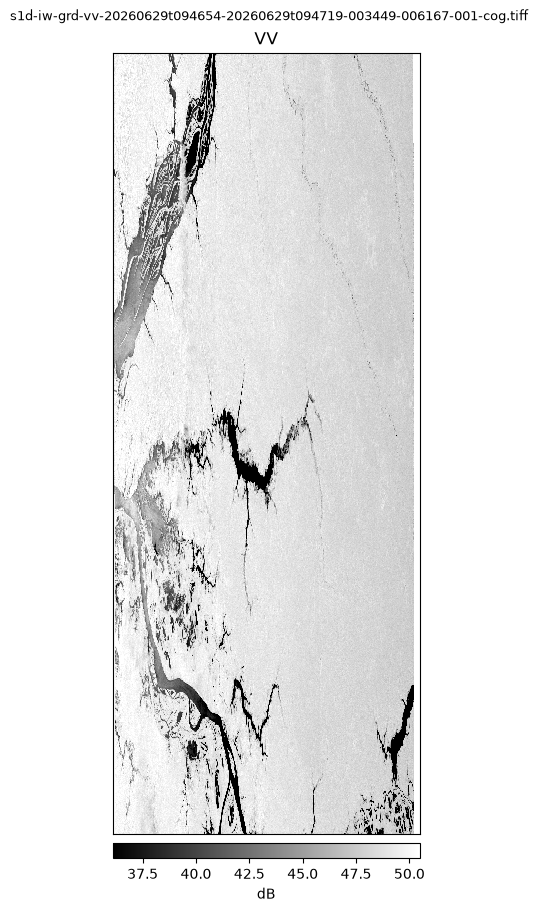

In [10]:
plot_raster(tiffs[0]);


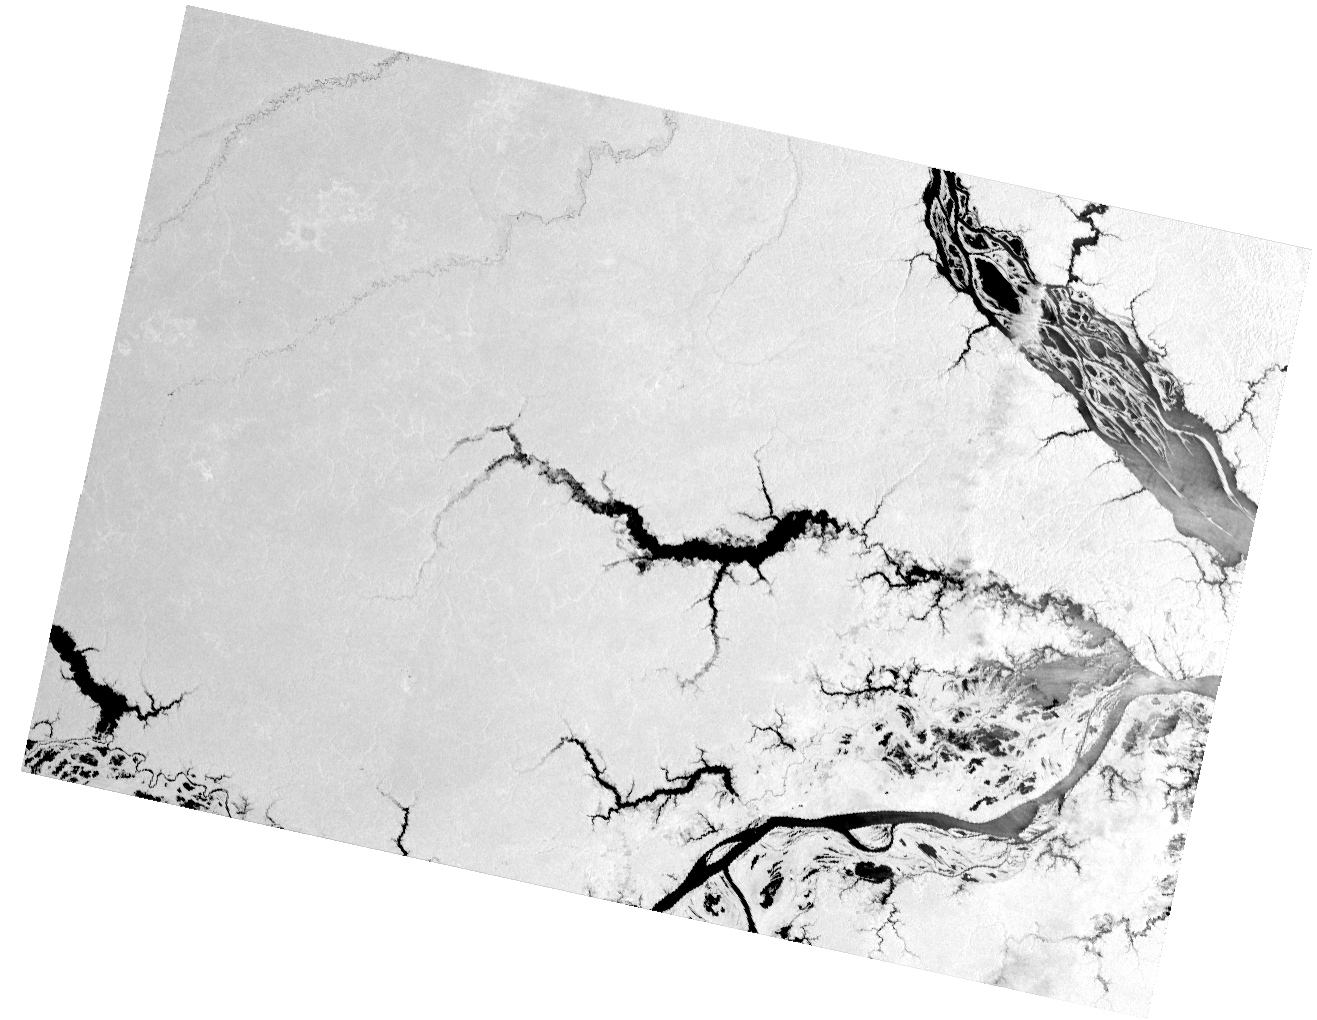

In [10]:
raster_map(tiffs)   # one layer per file; toggle them with the control in the top-right corner